In [16]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent)

print(Path.cwd())

d:\private\ai-research-paper-assistant


In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from src.utils.helpers import compute_mean_df

c:\Users\luann\miniconda3\envs\rag\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [71]:
folders_path = [r"D:\private\ai-research-paper-assistant\data\results_dense",
           r"D:\private\ai-research-paper-assistant\data\results_hybrid",
           r"D:\private\ai-research-paper-assistant\data\results_dense_rerank",
           r"D:\private\ai-research-paper-assistant\data\results_hybrid_rerank"]

contexts = []
retrieves = []
for folder_path in folders_path:
    name_method = "_".join(Path(folder_path).name.split('_')[1:])
    for file in os.listdir(folder_path):
        full_path = os.path.join(folder_path, file)
        name_file = file.split('.')[0]
        df = pd.read_csv(full_path, index_col=0)
        if name_file == "context_gen_results":
            meaned = {k: [float(v)] for k, v in compute_mean_df(df).items()}
            df_mean = pd.DataFrame(meaned)
            df_mean.insert(0, "Method", [name_method])
            contexts.append(df_mean)
        elif name_file == "retrieve_results":
            df.insert(0, "Method", [name_method])
            retrieves.append(df)

contexts_df = pd.concat(contexts, axis=0)
retrieves_df = pd.concat(retrieves, axis=0)


In [72]:
contexts_df.head()

,Method,context_precision,faithfulness,factual_correctness,Time
0,dense,0.938847,0.534109,0.5006,1.944998
0,hybrid,0.938847,0.534109,0.5006,1.932343
0,dense_rerank,0.955917,0.580774,0.5206,3.243443
0,hybrid_rerank,0.955917,0.580774,0.5206,3.061729


In [73]:
retrieves_df.head()

,Method,precision@5,recall@5,hit@5,mrr@5,map@5,ndcg@5
0,dense,0.184667,0.823778,0.836667,0.710278,0.699293,0.734065
0,hybrid,0.184667,0.823778,0.836667,0.710278,0.699293,0.734065
0,dense_rerank,0.172000,0.776944,0.793333,0.686556,0.671255,0.702298
0,hybrid_rerank,0.172000,0.776944,0.793333,0.686556,0.671255,0.702298


In [77]:
contexts_df.columns

Index(['Method', 'context_precision', 'faithfulness', 'factual_correctness',
       'Time'],
      dtype='object')

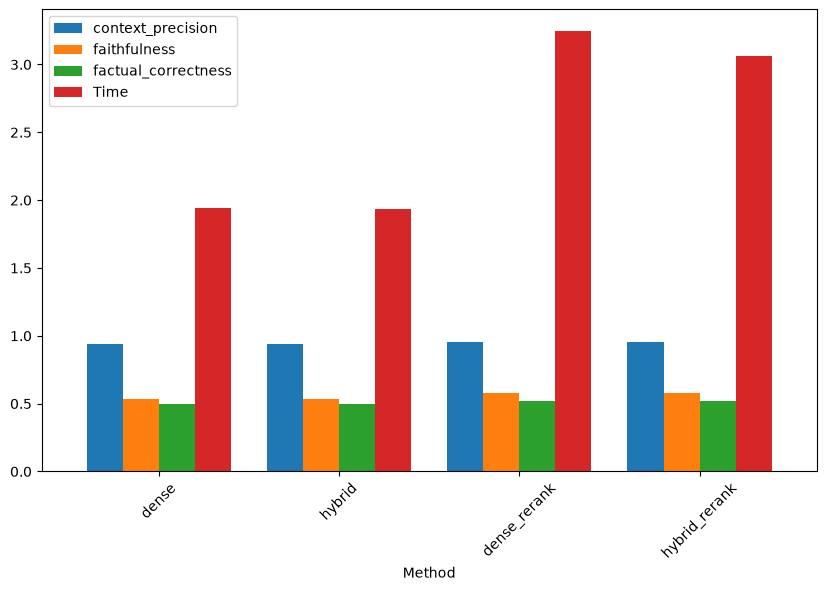

In [95]:
contexts_df.set_index("Method").plot(kind="bar", rot=45, figsize=(10, 6), width=0.8)
plt.show()

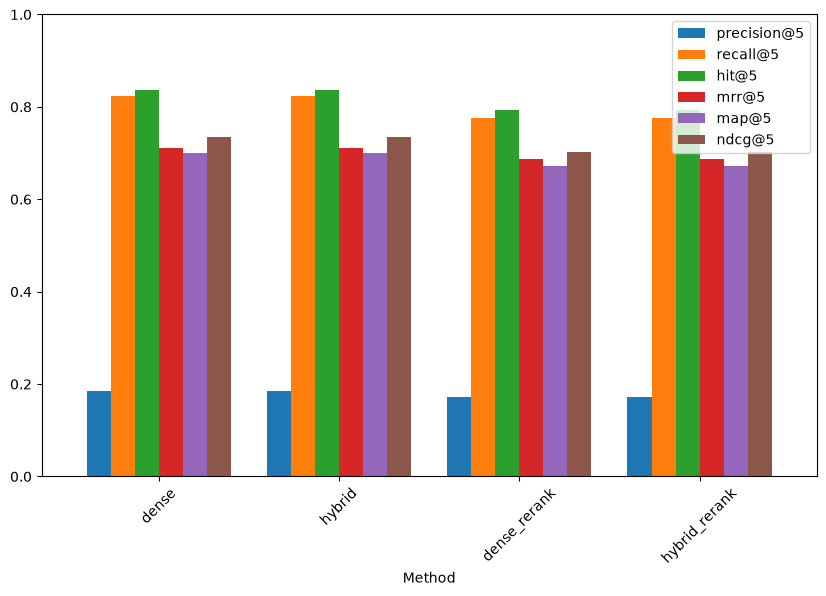

In [99]:
retrieves_df.set_index("Method").plot(kind="bar", rot=45, figsize=(10, 6), width=0.8, ylim=(0, 1))
plt.show()